# 01 — Data Preparation and Shared Split

In [1]:
import sys
from collections import Counter
from pathlib import Path

from IPython.display import display
from PIL import Image

# Locate the existing source directory from the kernel's working directory.
CWD = Path.cwd().resolve()
CANDIDATES = [candidate for parent in (CWD, *CWD.parents) for candidate in (parent, parent / "src")]
PACKAGE = next(
    (candidate for candidate in CANDIDATES if (candidate / "rukopys" / "data.py").is_file()),
    None,
)

if PACKAGE is None:
    raise FileNotFoundError(
        "Open the notebook from the project directory or one of its subdirectories. "
        "Place the rukopys package inside the existing src directory, next to work."
    )

ROOT = (PACKAGE / "work").resolve()
ROOT.mkdir(parents=True, exist_ok=True)

if str(PACKAGE) not in sys.path:
    sys.path.insert(0, str(PACKAGE))

from rukopys.config import TYPES
from rukopys.data import prepare_data
from rukopys.utils import digest, read_json

print("Source directory:", PACKAGE.name)
print("Experiment directory:", ROOT.relative_to(PACKAGE))

Source directory: src
Experiment directory: work


In [2]:
# Optional environment setup: uncomment only when dependencies are missing.
# Keep this disabled when reusing the existing environment and results.
# REQUIREMENTS = PACKAGE.parent / "requirements.txt"
# %pip install -q -r "{REQUIREMENTS}"

In [3]:
DATA = ROOT / "data"
PROJECT_PATH = ROOT / "project.json"
STATE_PATH = DATA / "preparation_state.json"
SPLIT_PATH = DATA / "split.json"

print("Using existing work directory:", ROOT.name)
print("Preparation state found:", STATE_PATH.is_file())

Using existing work directory: work
Preparation state found: True


## Data preparation

We use metadata and images from the dataset's training split only. The test split is not used for training.

All regions from the same page belong to the same partition. The existing split and dataset revision are reused to keep our experiments consistent.

Preparation includes all seven region types without the 10–150-character length filter. Invalid bounding boxes are recorded in `rejected.json`.

When preparation is complete and the saved configuration, manifests, and crop files are present, the notebook reuses them. Otherwise, preparation resumes using the existing page receipts and crops.

In [4]:
EXISTING_SPLIT = SPLIT_PATH if SPLIT_PATH.is_file() else None
DATASET_REVISION = read_json(PROJECT_PATH)["dataset_revision"] if PROJECT_PATH.is_file() else None
STATE = read_json(STATE_PATH) if STATE_PATH.is_file() else {}
MANIFEST_PATHS = {
    "train": DATA / "train.json",
    "validation": DATA / "validation.json",
    "pages": DATA / "pages.json",
    "rejected": DATA / "rejected.json",
}

if STATE and STATE.get("config", {}).get("root") != str(ROOT):
    raise ValueError(
        "The saved preparation state belongs to a different work directory. "
        "Use the original project location to preserve existing results."
    )

READY = (
    STATE.get("complete", False)
    and PROJECT_PATH.is_file()
    and SPLIT_PATH.is_file()
    and all(path.is_file() for path in MANIFEST_PATHS.values())
)

if READY:
    SAVED_SPLIT = read_json(SPLIT_PATH)
    CONFIG = STATE.get("config", {})

    if (
        STATE.get("dataset_revision") != DATASET_REVISION
        or SAVED_SPLIT.get("dataset_revision") != DATASET_REVISION
        or CONFIG.get("split_sha256") != digest(SAVED_SPLIT)
    ):
        raise ValueError("The saved split or dataset revision has changed.")

    SAVED_ROWS = {
        partition: read_json(MANIFEST_PATHS[partition]) for partition in ("train", "validation")
    }
    PROJECT = read_json(PROJECT_PATH)

    if any(
        digest(rows) != PROJECT.get(f"{partition}_manifest_sha256")
        for partition, rows in SAVED_ROWS.items()
    ):
        raise ValueError("A saved manifest differs from the project record.")

    READY = all(Path(row["crop_path"]).is_file() for rows in SAVED_ROWS.values() for row in rows)

if READY:
    print("Preparation is already complete; reusing saved crops and manifests.")
    print(
        {
            **{partition: len(rows) for partition, rows in SAVED_ROWS.items()},
            "rejected": len(read_json(MANIFEST_PATHS["rejected"])),
        }
    )
else:
    print(
        prepare_data(
            ROOT,
            seed=42,
            existing_split=EXISTING_SPLIT,
            revision=DATASET_REVISION,
        )
    )

Preparation is already complete; reusing saved crops and manifests.
{'train': 20569, 'validation': 5082, 'rejected': 0}


In [5]:
for partition in ("train", "validation"):
    rows = read_json(DATA / f"{partition}.json")
    page_count = len({row["page_id"] for row in rows})

    print(partition, "regions:", len(rows), "pages:", page_count)
    print("Types:", Counter(row["type"] for row in rows))
    print("Scorable:", Counter(row["type"] for row in rows if row["scorable"]))
    print("Sources:", Counter(row["source"] for row in rows))

print("Rejected:", len(read_json(DATA / "rejected.json")))

train regions: 20569 pages: 1062
Types: Counter({'handwritten': 17273, 'formula': 2377, 'annotation': 444, 'printed': 207, 'table': 117, 'image': 99, 'graph': 52})
Scorable: Counter({'handwritten': 17093, 'formula': 2174, 'annotation': 359, 'printed': 200, 'table': 112})
Sources: Counter({'school': 8330, 'dictation': 6718, 'university': 3245, 'archive': 2276})
validation regions: 5082 pages: 268
Types: Counter({'handwritten': 4304, 'formula': 515, 'annotation': 110, 'printed': 101, 'table': 25, 'image': 20, 'graph': 7})
Scorable: Counter({'handwritten': 4277, 'formula': 472, 'annotation': 95, 'printed': 88, 'table': 23})
Sources: Counter({'school': 2037, 'dictation': 1751, 'university': 811, 'archive': 483})
Rejected: 0


handwritten 'Магія голосу.' scorable: True


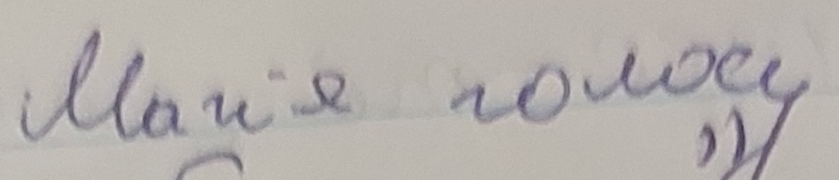

printed 'Всеукраїнський радіодиктант' scorable: True


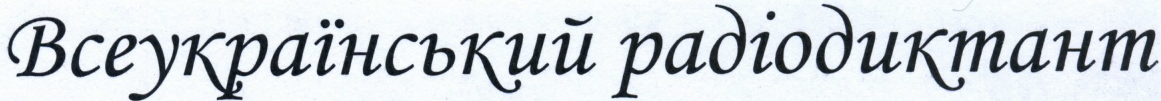

formula '6) R2 ⊕ R1' scorable: True


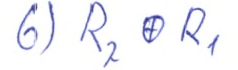

table '№|Наим. продуктов|Остаток на 7-е июня|7 Приход|7 Расход|8 Приход|8 Расход|9 Приход|9 Расход|10 Приход|10 Расход|11 Приход|11 Расход|12 Приход|12 Расход|Остаток на 13 июня\n1|Хліб|—|9п 10|4п 25р|—|4п 25р|10п|7п 32р|—|5п 08р|—|—|6п|—|6п.\n2|Картофель|5п 32ф|3|3п 05ф|10п|3п 05ф|—|3п 08|—|9п 14ф|—\n3|Пшено|6п 37 3/4|—|1п 25|—|—|—|1п 24 1/4|—|3п 30 1/2|—\n4|Бураки|6ф|—|6ф|—\n5|Белье|64 шт|—|64 шт|—' scorable: False


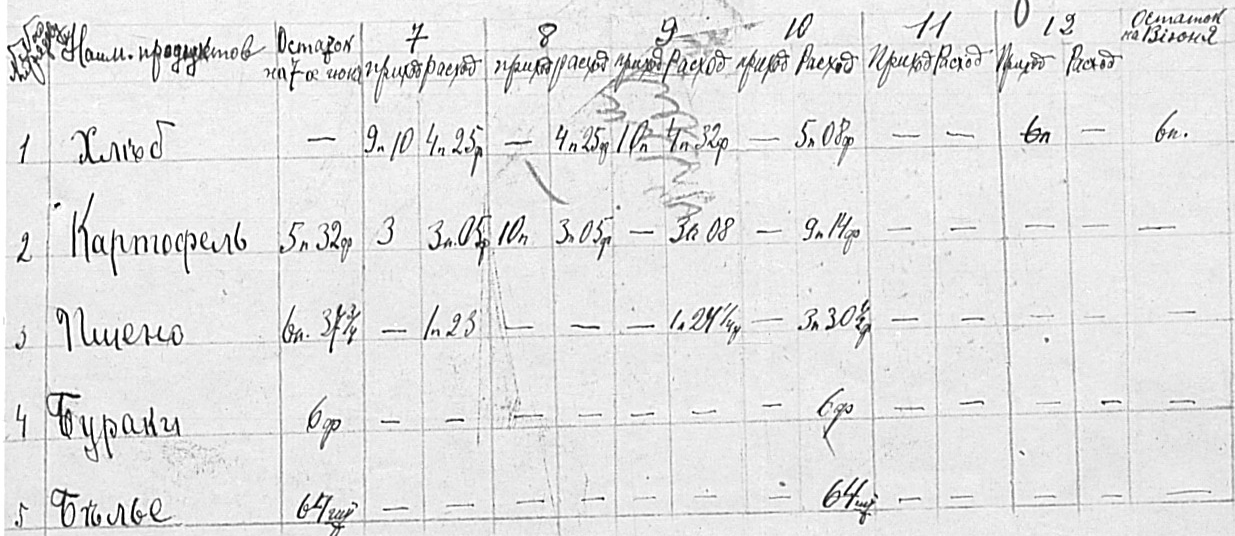

annotation '25.10.2024' scorable: True


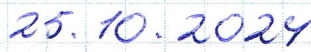

image '' scorable: False


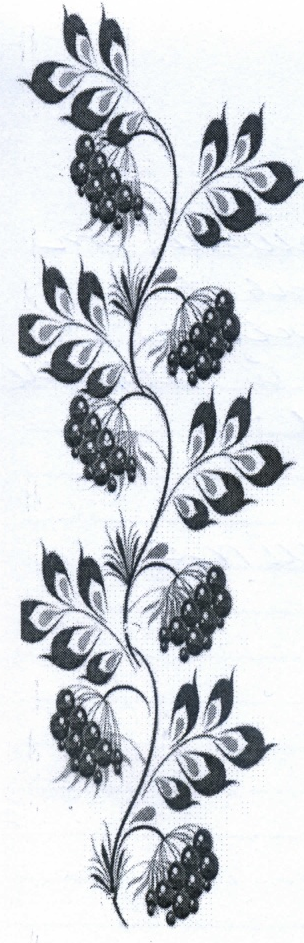

graph '' scorable: False


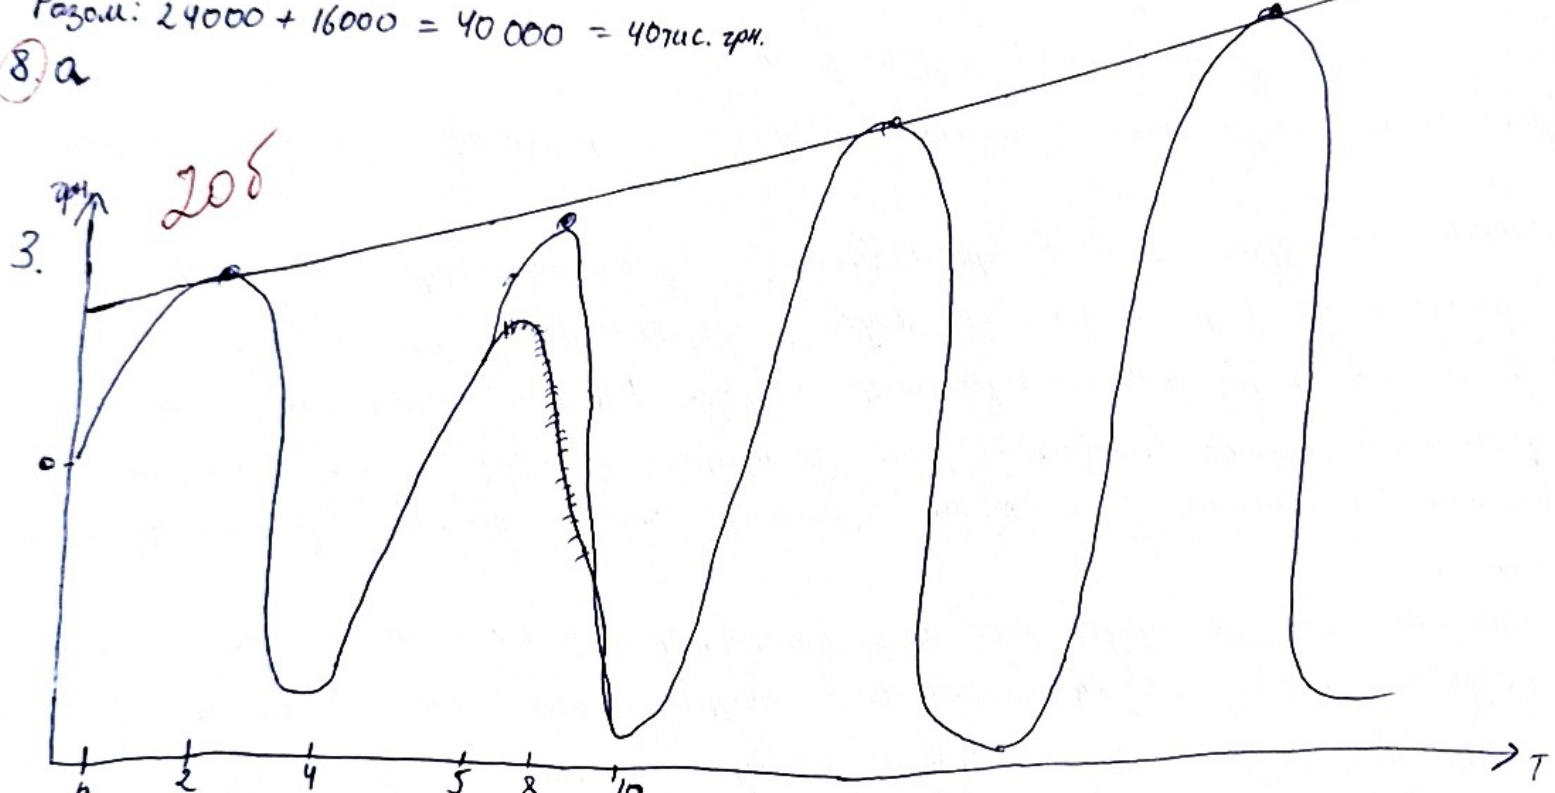

In [6]:
rows = read_json(DATA / "train.json")

for kind in TYPES:
    sample = next((row for row in rows if row["type"] == kind), None)

    if sample is not None:
        print(
            kind,
            repr(sample["reference"]),
            "scorable:",
            sample["scorable"],
        )

        with Image.open(sample["crop_path"]) as image:
            display(image.copy())